In [2]:
import re
from collections import Counter, defaultdict
from fractions import Fraction
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# ---- settings ----
INPUT_PATH = "recipes_clean.pkl"
MAX_MINUTES = 180
N_CHOSEN = 500                                
N_GRID = [100, 200, 300, 500, 700, 1000, 1500]

df = pd.read_pickle(INPUT_PATH)
print(df.shape)

funnel = [("start (from notebook 1)", len(df))]
def log(step, d):
    funnel.append((step, len(d)))
    print(f"{step}: {len(d):,} rows")

(84905, 19)


In [3]:
print(df["TotalTime_min"].describe(percentiles=[.5, .9, .95, .99]).round(1))
df = df[df["TotalTime_min"] <= MAX_MINUTES].copy()
log(f"1. TotalTime_min <= {MAX_MINUTES}", df)

count       84905.0
mean          711.5
std        149603.8
min             1.0
50%            35.0
90%           130.0
95%           250.0
99%          1450.0
max      43552800.0
Name: TotalTime_min, dtype: float64
1. TotalTime_min <= 180: 78,779 rows


In [4]:
def parse_qty(q):
    """'1 1/2' -> 1.5 ; '1/2 - 1' -> 0.75 ; unparseable -> NaN"""
    if q is None:
        return np.nan
    try:
        pieces = [p for p in str(q).split("-") if p.strip()]
        vals = [float(sum(Fraction(x) for x in p.split())) for p in pieces]
        return float(np.mean(vals)) if vals else np.nan
    except (ValueError, ZeroDivisionError):
        return np.nan

df["quants_num"] = df["quants"].apply(lambda l: [parse_qty(x) for x in l])
has_nan = df["quants_num"].apply(lambda l: any(np.isnan(x) for x in l))
print(f"Recipes with unparseable quantity: {has_nan.sum():,} ({has_nan.mean()*100:.2f}%)")

Recipes with unparseable quantity: 0 (0.00%)


In [5]:
DESCRIPTORS = {
    "fresh", "freshly", "chopped", "minced", "diced", "sliced", "large", "small",
    "medium", "finely", "coarsely", "roughly", "grated", "shredded", "crushed",
    "peeled", "uncooked", "optional", "divided", "packed", "softened",
    "melted", "boneless", "skinless", "frozen", "thawed", "chilled", "cold",
    "warm", "lukewarm", "extra", "of", "the", "a", "and",
}   
SPECIAL = {"chilies": "chili", "cookies": "cookie", "brownies": "brownie",
           "smoothies": "smoothie", "veggies": "veggie", "tomatoes": "tomato",
           "potatoes": "potato", "leaves": "leaf", "loaves": "loaf", "halves": "half"}
KEEP = {"molasses", "asparagus", "hummus", "couscous", "swiss", "grits", "citrus",
        "lemongrass", "watercress", "cress", "bass", "hops", "less"}


def singular(w):
    if w in SPECIAL:
        return SPECIAL[w]
    if w == "peas":
        return "pea"
    if w in KEEP or len(w) <= 3:
        return w
    if w.endswith("ies"):
        return w[:-3] + "y"
    if w.endswith(("ches", "shes", "xes")):
        return w[:-2]
    if w.endswith("s") and not w.endswith(("ss", "us", "is")):
        return w[:-1]
    return w


@lru_cache(maxsize=None)
def normalize_ingredient(name):
    s = str(name).lower()
    s = re.sub(r"\(.*?\)", " ", s)
    s = s.split(",")[0]
    s = re.sub(r"[\d_]", " ", s)
    s = s.replace("'", "")
    s = re.sub(r"[^\w\s-]", " ", s)
    tokens = [t for t in re.split(r"[\s-]+", s) if t and t not in DESCRIPTORS]
    if not tokens:
        return str(name).lower().strip()
    tokens[-1] = singular(tokens[-1])
    return " ".join(tokens)

In [16]:
 # Merge dictionary: canonical name -> list of variants that get merged into it
ALIAS_GROUPS = {
    "all purpose flour": ["flour", "plain flour", "unbleached all purpose flour", "white flour"],
    "self rising flour": ["self raising flour"],
    "butter": ["unsalted butter"],
    "sugar": ["granulated sugar", "white sugar", "caster sugar"],
    "powdered sugar": ["confectioners sugar", "icing sugar"],
    "brown sugar": ["light brown sugar", "dark brown sugar"],
    "vanilla extract": ["vanilla", "pure vanilla extract", "vanilla essence"],
    "salt": ["kosher salt", "sea salt", "coarse salt", "table salt"],
    "garlic": ["garlic clove"],
    "onion": ["yellow onion", "sweet onion", "red onion"],
    "green onion": ["scallion"],
    "tomato": ["plum tomato", "roma tomato", "cherry tomato"],
    "green bell pepper": ["green pepper", "bell pepper"],
    "black pepper": ["pepper", "ground pepper", "ground black pepper", "coarse ground black pepper"],
    "cayenne pepper": ["cayenne"],
    "chicken breast": ["chicken breast half", "chicken breast halve"],
    "cheddar cheese": ["sharp cheddar cheese"],
    "olive oil": ["virgin olive oil"],
    "lemon zest": ["lemon rind", "lemon peel"],
    "cinnamon": ["ground cinnamon"],
    "nutmeg": ["ground nutmeg"],
    "cumin": ["ground cumin"],
    "allspice": ["ground allspice"],
    "clove": ["ground clove", "whole clove"],
    "ginger": ["gingerroot"],
    "rolled oat": ["oat", "quick cooking oat", "quick oat", "old fashioned oat"],
    "shortening": ["vegetable shortening"],
    "heavy cream": ["heavy whipping cream"],
    "skim milk": ["nonfat milk"],
    "white wine": ["dry white wine"],
    "white vinegar": ["vinegar"],
    "apple cider vinegar": ["cider vinegar"],
    "chicken broth": ["low sodium chicken broth"],
    "peanut butter": ["creamy peanut butter"],
    "cornmeal": ["yellow cornmeal"],
    "white rice": ["rice", "long grain rice"],
    "applesauce": ["unsweetened applesauce"],
    "pumpkin puree": ["canned pumpkin"],
    "corn": ["corn kernel"],
    "broccoli": ["broccoli floret"],
    "parsley": ["flat leaf parsley"],
    "basil": ["basil leaf"],
    "mint": ["mint leaf"],
    "dill": ["dill weed"],
    "mustard": ["prepared mustard"],
    "potato": ["russet potato", "baking potato"],
    "apple": ["granny smith apple"],
    "ground beef": ["lean ground beef"],
    "egg": ["hard boiled egg"],
    "pecan": ["pecan halve", "pecan half"],
    "active dry yeast": ["dry yeast"],
    "splenda": ["splenda sugar substitute", "splenda granular"],
    "water": ["boiling water", "hot water"],
    "plain yogurt": ["yogurt"],
}
ALIAS_GROUPS.update({
    "lentil": ["red lentil", "dried lentil", "dry lentil", "green lentil", "brown lentil"],
    "tofu": ["firm tofu", "silken tofu", "soft tofu", "firm silken tofu", "soft silken tofu"],
    "kale": ["kale leaf"],
    "tuna": ["tuna in water", "canned tuna", "albacore tuna in water", "tuna in vegetable oil"],
    "flax seed": ["ground flax seed", "flax seed meal"],
    "cashew": ["raw cashew", "cashew nut", "salted cashew", "unsalted cashew", "roasted cashew"],
    "sunflower seed": ["roasted sunflower seed", "unsalted sunflower seed", "dry roasted sunflower seed"],
    "clam": ["littleneck clam", "baby clam", "canned clam"],
})
ALIAS = {v: k for k, vs in ALIAS_GROUPS.items() for v in vs}
ALIAS = {v: k for k, vs in ALIAS_GROUPS.items() for v in vs}


@lru_cache(maxsize=None)
def canon(name):
    n = normalize_ingredient(name)
    return ALIAS.get(n, n)


# quick test
for t in ["lemons, rind of", "Unsalted butter", "pecan halves", "cooked rice", "rice",
          "Fresh ground black pepper", "chicken breast halves", "quick-cooking oats"]:
    print(f"{t!r:32} -> {canon(t)!r}")

'lemons, rind of'                -> 'lemon'
'Unsalted butter'                -> 'butter'
'pecan halves'                   -> 'pecan'
'cooked rice'                    -> 'cooked rice'
'rice'                           -> 'white rice'
'Fresh ground black pepper'      -> 'black pepper'
'chicken breast halves'          -> 'chicken breast'
'quick-cooking oats'             -> 'rolled oat'


In [17]:
df["parts_norm"] = df["parts"].apply(lambda l: [canon(x) for x in l])

# Which keys in the dictionary didn't match the data? (to make sure they're spelled correctly)
seen_normalized = set(normalize_ingredient(x) for x in df["parts"].explode().dropna().unique())
unused = sorted(k for k in ALIAS if k not in seen_normalized)
print(f"Alias keys not found in data ({len(unused)}):", unused)

n_raw = df["parts"].explode().str.lower().nunique()
n_norm = df["parts_norm"].explode().nunique()
print(f"\nUnique ingredient names: raw={n_raw:,} -> normalized+merged={n_norm:,}")

Alias keys not found in data (1): ['pecan halve']

Unique ingredient names: raw=4,710 -> normalized+merged=3,798


Top 30: [('salt', 37761), ('butter', 27347), ('sugar', 25583), ('all purpose flour', 21940), ('egg', 21690), ('black pepper', 14985), ('water', 14765), ('onion', 14746), ('garlic', 14042), ('vanilla extract', 12589), ('olive oil', 12456), ('milk', 11257), ('brown sugar', 11117), ('baking powder', 10203), ('cinnamon', 9602), ('baking soda', 8376), ('lemon juice', 8001), ('tomato', 5764), ('margarine', 5361), ('parsley', 4344), ('nutmeg', 4100), ('parmesan cheese', 4078), ('cream cheese', 3918), ('honey', 3910), ('sour cream', 3880), ('green onion', 3753), ('carrot', 3683), ('powdered sugar', 3594), ('pecan', 3589), ('cheddar cheese', 3523)]


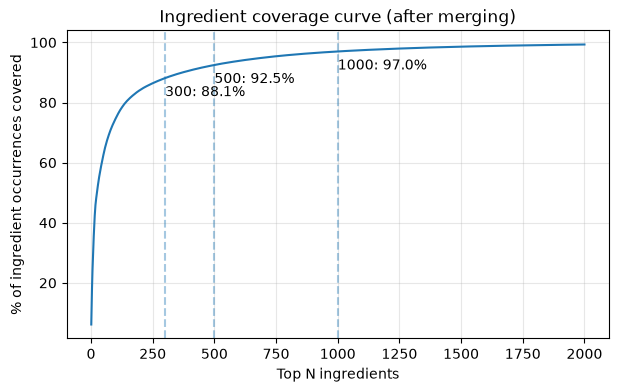

In [18]:
ing_counts = Counter()
raw_variants = defaultdict(Counter)

for raws, norms in zip(df["parts"], df["parts_norm"]):
    for r, n in zip(raws, norms):
        raw_variants[n][r.lower()] += 1
    ing_counts.update(set(norms))

ranked = [ing for ing, _ in ing_counts.most_common()]
rank = {ing: i + 1 for i, ing in enumerate(ranked)}
total_occ = sum(ing_counts.values())
cum = np.cumsum([ing_counts[i] for i in ranked]) / total_occ * 100

print("Top 30:", ing_counts.most_common(30))

M = min(2000, len(cum))
plt.figure(figsize=(7, 4))
plt.plot(range(1, M + 1), cum[:M])
for n in (300, 500, 1000):
    if n <= len(cum):
        plt.axvline(n, linestyle="--", alpha=0.4)
        plt.text(n, cum[n - 1] - 6, f"{n}: {cum[n-1]:.1f}%")
plt.xlabel("Top N ingredients")
plt.ylabel("% of ingredient occurrences covered")
plt.title("Ingredient coverage curve (after merging)")
plt.grid(alpha=0.3)
plt.show()

In [24]:
FORCE_INCLUDE = [
    "lentil", "tofu", "kale", "quinoa", "tuna",
     "flax seed", "cashew", "sunflower seed",
]
SEARCH_KEYWORDS = ["lentil", "tofu", "kale", "quinoa", "almond", "orange juice", "tuna",
                   "steak", "pumpkin seed", "flax", "cashew", "sunflower", "chia", "tempeh", "oyster", "clam"]

print("== FORCE_INCLUDE status ==")
for ing in FORCE_INCLUDE:
    if ing in rank:
        print(f"  OK   {ing:20} rank={rank[ing]:5}  recipes={ing_counts[ing]}")
    else:
        print(f"  MISSING {ing}  (Not found in the data under this name)")

print("\n== Keyword suggestions (top 6 matches per keyword) ==")
for kw in SEARCH_KEYWORDS:
    hits = sorted(((i, c) for i, c in ing_counts.items() if kw in i), key=lambda x: -x[1])[:6]
    print(f"  {kw:14}", [(i, c, rank[i]) for i, c in hits])

== FORCE_INCLUDE status ==
  OK   lentil               rank=  190  recipes=355
  OK   tofu                 rank=  164  recipes=442
  OK   kale                 rank=  304  recipes=185
  OK   quinoa               rank=  307  recipes=183
  OK   tuna                 rank=  209  recipes=306
  OK   flax seed            rank=  177  recipes=411
  OK   cashew               rank=  189  recipes=363
  OK   sunflower seed       rank=  216  recipes=281

== اقتراحات بالكلمات المفتاحية (أعلى 6 تطابقات لكل كلمة) ==
  lentil         [('lentil', 355, 190), ('dry green lentil', 13, 1465), ('dried red lentil', 10, 1667), ('dried brown lentil', 9, 1760), ('french lentil', 7, 1850), ('yellow lentil', 4, 2297)]
  tofu           [('tofu', 442, 164), ('tofutti better than cream cheese', 7, 1950), ('tofutti sour cream', 5, 2212), ('low fat tofu', 4, 2320), ('reduced fat firm tofu', 4, 2342), ('lowfat silken tofu', 3, 2525)]
  kale           [('kale', 185, 304)]
  quinoa         [('quinoa', 183, 307)]
  almond   

In [25]:
IMPORTANT = [
    # Iron
    "spinach", "chickpea", "black bean", "kidney bean", "ground beef", "ground turkey", "shrimp",
    "salmon fillet", "molasses", "raisin", "date", "tahini", "sesame seed", "pine nut", "chicken thigh",
    # Vitamin C
    "red bell pepper", "broccoli", "lemon juice", "lemon", "lime juice", "orange", "strawberry", "pineapple",
    "tomato", "cabbage", "cauliflower", "parsley", "cilantro", "asparagus", "potato", "sweet potato",
    "mango", "avocado", "green bean", "cranberry",
]
rows = []
for ing in IMPORTANT:
    if ing in rank:
        rows.append({"ingredient": ing, "rank": rank[ing], "recipes": ing_counts[ing],
                     f"within_top_{N_CHOSEN}": rank[ing] <= N_CHOSEN})
    else:
        rows.append({"ingredient": ing, "rank": None, "recipes": 0, f"within_top_{N_CHOSEN}": False})
pd.DataFrame(rows)

,ingredient,rank,recipes,within_top_500
0,spinach,75,1436,True
1,chickpea,178,407,True
2,black bean,132,708,True
3,kidney bean,198,332,True
4,ground beef,61,1832,True
5,ground turkey,199,330,True
6,shrimp,111,945,True
7,salmon fillet,173,416,True
8,molasses,98,1043,True
9,raisin,53,2254,True


In [26]:
forced_set = {i for i in FORCE_INCLUDE if i in rank}

def eff_rank(x):
    return 0 if x in forced_set else rank[x]

df["max_rank"] = df["parts_norm"].apply(lambda l: max(eff_rank(x) for x in l))
df["max_rank_no_force"] = df["parts_norm"].apply(lambda l: max(rank[x] for x in l))

rows = []
for n in N_GRID:
    kept = int((df["max_rank"] <= n).sum())
    kept_nf = int((df["max_rank_no_force"] <= n).sum())
    rows.append({
        "N": n,
        "occurrence_coverage_%": round(float(cum[min(n, len(cum)) - 1]), 1),
        "recipes_kept": kept,
        "recipes_kept_no_force": kept_nf,
        "% of current recipes": round(kept / len(df) * 100, 1),
    })
n_table = pd.DataFrame(rows)
n_table

,N,occurrence_coverage_%,recipes_kept,recipes_kept_no_force,% of current recipes
0,100,74.7,13796,13506,17.5
1,200,84.2,26795,26539,34.0
2,300,88.1,34748,34596,44.1
3,500,92.5,46145,46145,58.6
4,700,95.0,54831,54831,69.6
5,1000,97.0,63319,63319,80.4
6,1500,98.6,70995,70995,90.1


In [27]:
final = df[df["max_rank"] <= N_CHOSEN].copy()
log(f"2. all ingredients within top {N_CHOSEN} or forced (tolerance 0)", final)

print("\nTail of the list (ranks near N_CHOSEN):")
print([(ranked[i], ing_counts[ranked[i]]) for i in range(max(0, N_CHOSEN - 12), min(N_CHOSEN, len(ranked)))])

2. all ingredients within top 500 or forced (tolerance 0): 46,145 rows

Tail of the list (ranks near N_CHOSEN):
[('granola cereal', 100), ('chipotle chile in adobo', 100), ('saffron thread', 100), ('shell pasta', 100), ('cognac', 99), ('toasted sesame seed', 99), ('turnip', 99), ('pimento', 99), ('crisco shortening', 99), ('penne', 99), ('low fat cream cheese', 99), ('red potato', 99)]


In [28]:
final_ings = Counter()
for norms in final["parts_norm"]:
    final_ings.update(set(norms))

ing_table = pd.DataFrame(
    [{"rank": rank[i], "ingredient": i, "n_recipes": c,
      "forced": (i in forced_set and rank[i] > N_CHOSEN),
      "raw_variants": " | ".join(v for v, _ in raw_variants[i].most_common(3)),
      "usda_description": "", "usda_id": "", "notes": ""}
     for i, c in final_ings.items()]
).sort_values("rank").reset_index(drop=True)

ing_table.to_csv("ingredients_to_map.csv", index=False, encoding="utf-8-sig")
print(f"{len(ing_table)} ingredients to map ({int(ing_table['forced'].sum())} forced beyond rank {N_CHOSEN})")
ing_table.head(15)

500 ingredients to map (0 forced beyond rank 500)


,rank,ingredient,n_recipes,forced,raw_variants,usda_description,usda_id,notes
0,1,salt,24070,False,salt | kosher salt | sea salt,,,
1,2,butter,19213,False,butter | unsalted butter,,,
2,3,sugar,17759,False,sugar | granulated sugar | white sugar,,,
3,4,all purpose flour,16346,False,flour | all-purpose flour | plain flour,,,
4,5,egg,15584,False,eggs | egg | hard-boiled eggs,,,
5,6,black pepper,8047,False,pepper | black pepper | fresh ground black pepper,,,
6,7,water,8156,False,water | boiling water | warm water,,,
7,8,onion,7223,False,onion | onions | red onion,,,
8,9,garlic,6802,False,garlic cloves | garlic | garlic clove,,,
9,10,vanilla extract,9588,False,vanilla | vanilla extract | pure vanilla extract,,,


In [29]:
FINAL_COLS = ["RecipeId", "Name", "RecipeCategory", "TotalTime_min", "RecipeServings",
              "has_servings", "parts", "parts_norm", "quants", "quants_num",
              "n_ingredients", "Calories", "FatContent", "SaturatedFatContent",
              "CholesterolContent", "SodiumContent", "CarbohydrateContent",
              "FiberContent", "SugarContent", "ProteinContent"]
FINAL_COLS = [c for c in FINAL_COLS if c in final.columns]

final = final[FINAL_COLS].reset_index(drop=True)
final.to_pickle("recipes_candidates.pkl")
print(final.shape)

pd.DataFrame(funnel, columns=["step", "n_recipes"])

(46145, 20)


,step,n_recipes
0,start (from notebook 1),84905
1,1. TotalTime_min <= 180,78779
2,2. all ingredients within top 500 or forced (tolerance 0),45603
3,2. all ingredients within top 500 or forced (tolerance 0),46145
4,2. all ingredients within top 500 or forced (tolerance 0),46145
